# 14 · HST vs Legacy Surveys vs the mock WCC frame

The same 52" x 35" patch of **COSMOS** in three data sets:

| | pixel | resolution | where it comes from |
|---|---|---|---|
| **HST ACS F606W** (CANDELS) | 30 mas | PSF FWHM ~0.1" | MAST HLSP mosaic, read by HTTP byte-range |
| **DESI Legacy Surveys DR10, r** | 262 mas | seeing ~1" | legacysurvey.org cutout service |
| **mock WCC `zwo:r`** | 16.9 mas | PSF FWHM ~50 mas | `simulate_field`, galaxies from the LS Tractor catalog |

The mock's galaxies are *smooth Sersic fits to the LS-DR10 images*, so it can only be as good as what LS resolved.
Putting real HST beside it shows what that smoothing loses.

The first run downloads about 130 MB of HST rows (several minutes, the archive is slow); everything is cached in
`ls_cache/` afterwards. The helpers are in `scripts/` (`candels_cutout.py`, `legacysurvey_galaxy_mock.py`).

In [1]:
import os, sys, warnings
import numpy as np
import matplotlib.pyplot as plt
from reproject import reproject_interp
from scipy.ndimage import gaussian_filter

sys.path.insert(0, os.path.abspath("../scripts"))
import legacysurvey_galaxy_mock as lsm
import hst_catalog_mock as hcm
from candels_cutout import fetch_candels_cutout
from matplotlib.patches import Ellipse
from wcc_sim import detector_frame, simulate_field
from wcc_sim.catalog import query_gaia
from wcc_sim.starflux import REF_MAG, rate_for_ab

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
# noisy images compress far better as JPEG than PNG (keeps the saved notebook small)
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}

## Settings

The default pointing is the COSMOS centre, which lies inside the CANDELS ACS mosaic (about 14' x 36' around
RA 150.12, Dec +2.35). CANDELS covers only part of COSMOS, so another position may fall outside it.

In [2]:
RA, DEC = lsm.COSMOS
SENSORFILTER = "zwo:r"
HST_BAND = "f606w"            # f606w (closest to r), f814w; WFC3 f125w / f160w are 60 mas
SHAPE = (2048, 3072)          # WCC subarray (ny, nx) = 34.5" x 51.8"
EXPTIME = 300.0
CACHE = "ls_cache"
LS_NPIX = 256                 # 256 px x 0.262" = 67", covers the patch

frame = detector_frame(SENSORFILTER, (RA, DEC), shape=SHAPE)
ny, nx = frame.shape
pix = frame.plate_scale_mas / 1000.0
width, height = nx * pix, ny * pix
print(f"patch {width:.1f}\" x {height:.1f}\" centred on ({RA}, {DEC})")

patch 51.8" x 34.5" centred on (150.12, 2.2)


## 1. Fetch the HST and Legacy Surveys cutouts

In [3]:
hst, hst_wcs, hst_zp, hst_hdr = fetch_candels_cutout(RA, DEC, width, height, HST_BAND, cache_dir=CACHE)
hst_exp, _, _, _ = fetch_candels_cutout(RA, DEC, width, height, HST_BAND, cache_dir=CACHE, kind="exp")  # exposure-time map, s
ls, ls_wcs = lsm.fetch_ls_cutout(RA, DEC, LS_NPIX * 0.262, band="r", npix=LS_NPIX)
print("HST", hst.shape, "px at 0.030\"  |  LS", ls.shape, "px at 0.262\"")

HST (1152, 1727) px at 0.030"  |  LS (256, 256) px at 0.262"


## 2. Build and simulate the mock

Tractor galaxies (DR10) become Sersic components, with the Gaia stars underneath (see notebook 13).

In [4]:
half_diag = 0.5 * np.hypot(nx, ny) * pix
tractor = lsm.fetch_tractor(RA, DEC, half_diag + lsm.QUERY_MARGIN_ARCSEC, cache_dir=CACHE)
comps, truth = lsm.tractor_to_sersic(tractor, frame, SENSORFILTER)
field = simulate_field(RA, DEC, sensorfilter=SENSORFILTER, exptime=EXPTIME, shape=SHAPE, seed=1,
                       extended_sources=comps, cache_dir=os.path.join(CACHE, "gaia"))
print(len(comps), "Sersic galaxies,", len(field.catalog), "Gaia stars")

123 Sersic galaxies, 2 Gaia stars


## 3. Put everything on one grid and one unit

Each image is converted to AB surface brightness in nanomaggies per arcsec^2 (HST from its PHOTFLAM zero point, LS is
already nanomaggies, the mock from its electron rate) and interpolated onto the WCC pixel grid, so the panels share a
sky position, a pixel scale and a colour stretch. The three are different bands (F606W, LS r and the `zwo:r`
passband), so colours shift the fluxes a little; the mock matches LS r by construction.

In [5]:
def to_grid(data, wcs):
    out, _ = reproject_interp((data, wcs), frame.wcs, shape_out=frame.shape, order="bilinear")
    return out

hst_nmgy = hst * 10.0 ** (0.4 * (22.5 - hst_zp))
hst_sb = to_grid(hst_nmgy / 0.030**2, hst_wcs)
ls_sb = to_grid(ls / 0.262**2, ls_wcs)

rate_ref = rate_for_ab(REF_MAG, SENSORFILTER)           # e-/s of an AB = REF_MAG source
def rate_to_nmgy(rate):
    return 10.0 ** (0.4 * (22.5 - REF_MAG)) * rate / rate_ref
mock_sb = rate_to_nmgy(field.image_clean / EXPTIME) / pix**2

hst_sb, ls_sb, mock_sb = (a - np.nanmedian(a) for a in (hst_sb, ls_sb, mock_sb))
print("fraction of grid with HST / LS data:", np.isfinite(hst_sb).mean().round(3), np.isfinite(ls_sb).mean().round(3))

fraction of grid with HST / LS data: 1.0 1.0


## 4. Simulated WCC stacks (noisy, as observed)

The same Tractor Sersic mock "observed" for 1 h, 3 h and 10 h as stacks of `FRAME_LEN`-second frames.
`simulate_field(exptime=T, n_reads=T / FRAME_LEN)` applies the simulator's own noise to the stack: Poisson noise on
source plus sky plus dark, read noise once per frame, and saturation judged per frame. Each depth uses its own
noise seed, so the three images are independent realisations. Section 9 explains why the frame length matters.

In [6]:
FRAME_LEN = 900.0
STACK_HOURS = (1, 3, 10)
stacks = {}
for seed, hours in enumerate(STACK_HOURS, start=11):
    T = hours * 3600.0
    n_frames = int(round(T / FRAME_LEN))
    stack = simulate_field(RA, DEC, sensorfilter=SENSORFILTER, exptime=T, n_reads=n_frames, shape=SHAPE,
                           seed=seed, extended_sources=comps, cache_dir=os.path.join(CACHE, "gaia"))
    sb_ = rate_to_nmgy(stack.image_e / T) / pix**2
    stacks[hours] = sb_ - np.nanmedian(sb_)
    print(f"{hours:>2} h = {n_frames} x {FRAME_LEN:.0f} s: {int(stack.saturation_mask.sum())} saturated pixels, "
          f"background rms {np.nanstd(stacks[hours][:200, :200]):.3f} nmgy/arcsec^2 per 17 mas pixel")

 1 h = 4 x 900 s: 0 saturated pixels, background rms 0.247 nmgy/arcsec^2 per 17 mas pixel


 3 h = 12 x 900 s: 0 saturated pixels, background rms 0.143 nmgy/arcsec^2 per 17 mas pixel


10 h = 40 x 900 s: 0 saturated pixels, background rms 0.078 nmgy/arcsec^2 per 17 mas pixel


## 5. The patches side by side (same stretch)

HST and DESI Legacy Surveys DR10, then the simulated WCC stacks at 1 h, 3 h and 10 h, and finally the noise-free
mock for reference. Everything is on the WCC pixel grid and in the same brightness units, with one stretch
(set by the brightest 0.2% of HST pixels). WCC pixels are shown unbinned; HST and WCC are both noisy at this scale.

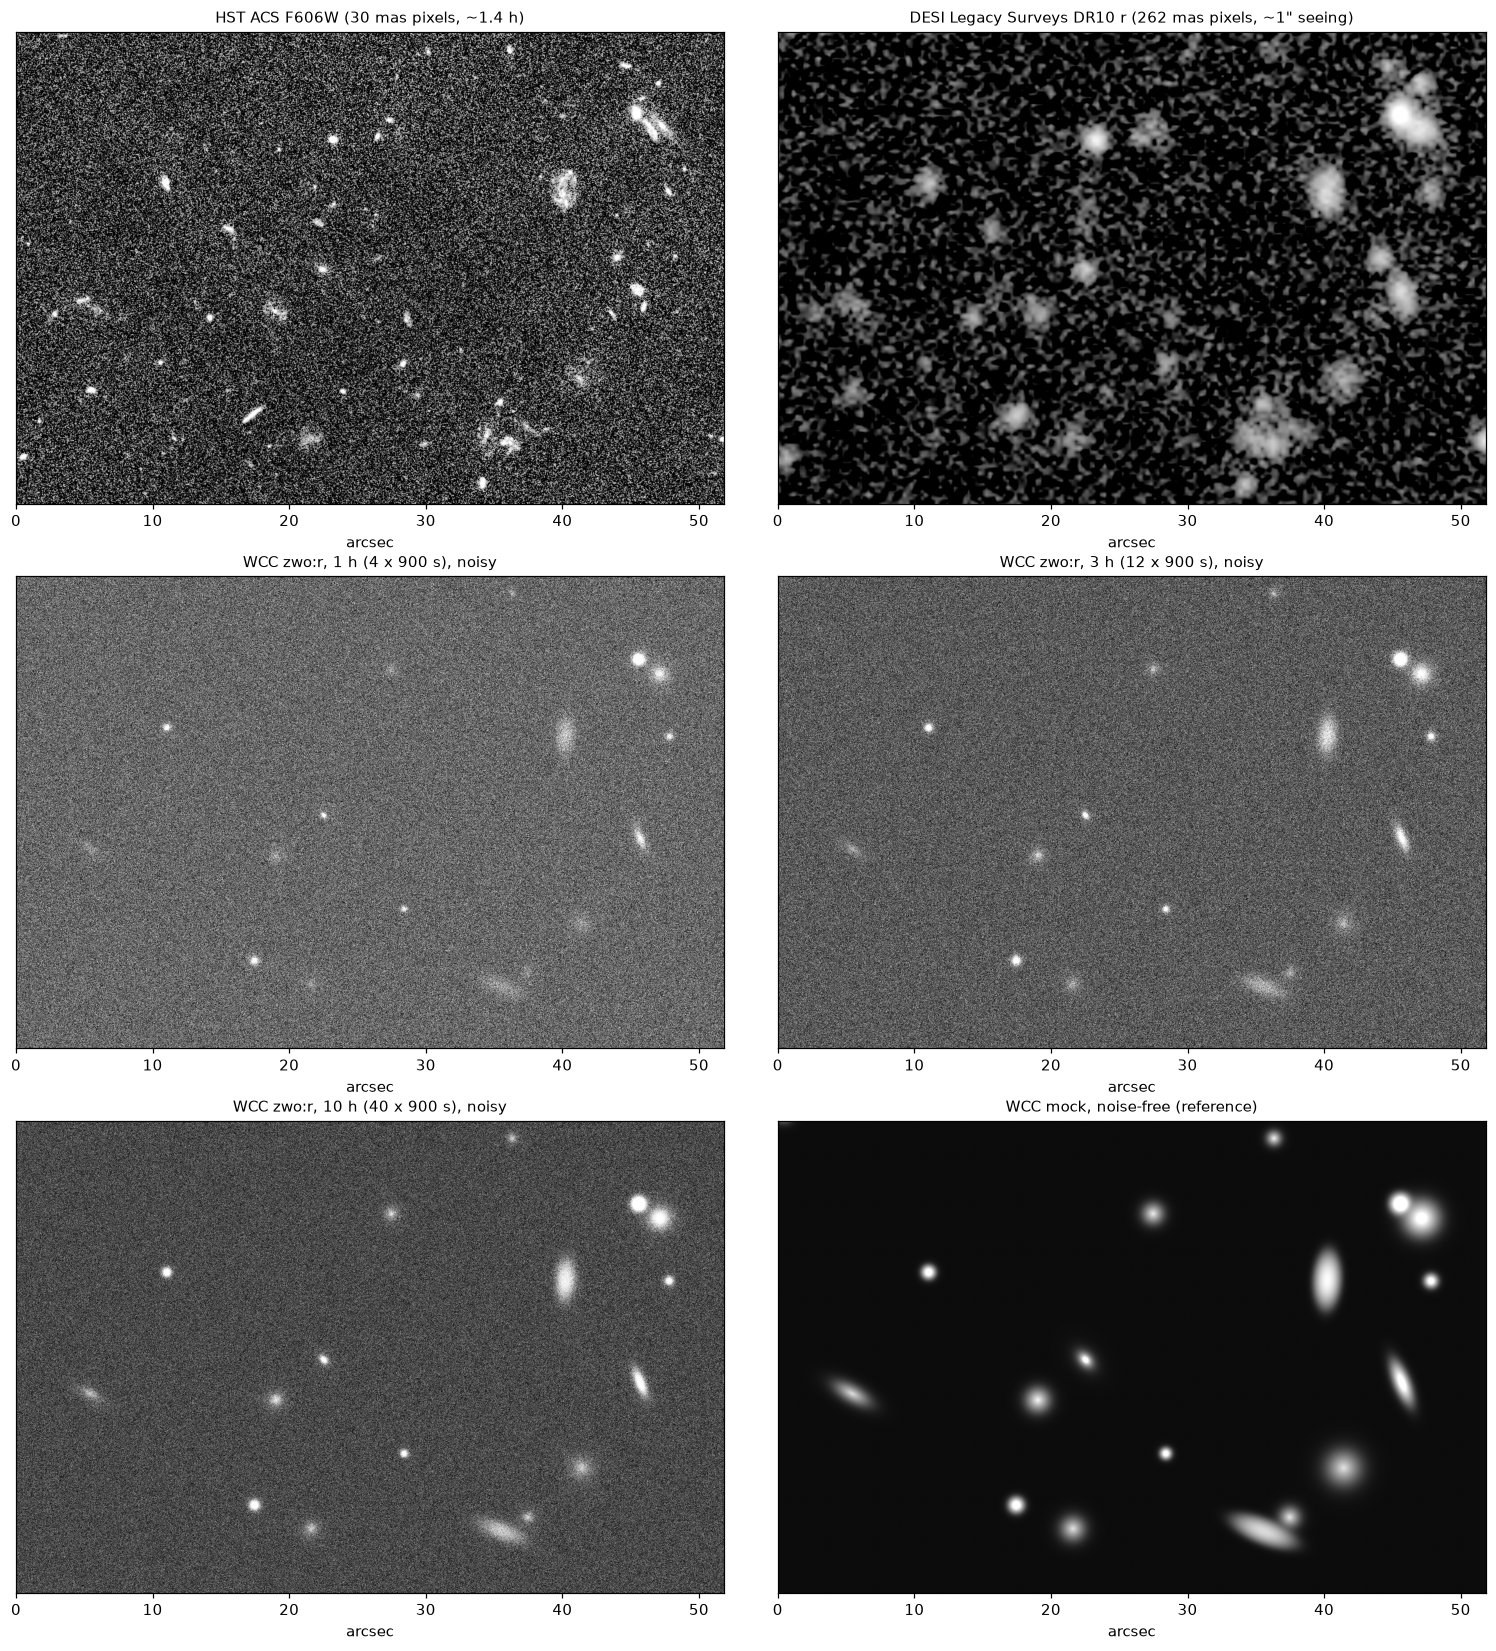

In [7]:
HI = np.nanpercentile(hst_sb, 99.8)       # the one brightness stretch used by every panel
def show(ax, img, title):
    ax.imshow(np.arcsinh(np.nan_to_num(img) / HI * 30.0) / np.arcsinh(30.0), origin="lower",
              cmap="gray", vmin=-0.05, vmax=1, extent=(0, width, 0, height))
    ax.set_title(title, fontsize=10); ax.set_xlabel('arcsec'); ax.set_yticks([])

fig, axes = plt.subplots(3, 2, figsize=(14, 3 * 7.0 * height / width + 1.0))
show(axes[0, 0], hst_sb, f"HST ACS {HST_BAND.upper()} (30 mas pixels, ~{np.median(hst_exp)/3600:.1f} h)")
show(axes[0, 1], ls_sb, "DESI Legacy Surveys DR10 r (262 mas pixels, ~1\" seeing)")
for ax, hours in zip((axes[1, 0], axes[1, 1], axes[2, 0]), STACK_HOURS):
    show(ax, stacks[hours], f"WCC {SENSORFILTER}, {hours} h ({int(round(hours * 3600 / FRAME_LEN))} x {FRAME_LEN:.0f} s), noisy")
show(axes[2, 1], mock_sb, "WCC mock, noise-free (reference)")
fig.tight_layout()

## 6. Zoom on individual galaxies

The three largest resolved galaxies among the brightest in the frame. Columns: HST, LS-DR10 and the noise-free mock,
each on the WCC pixel grid with one stretch per row.

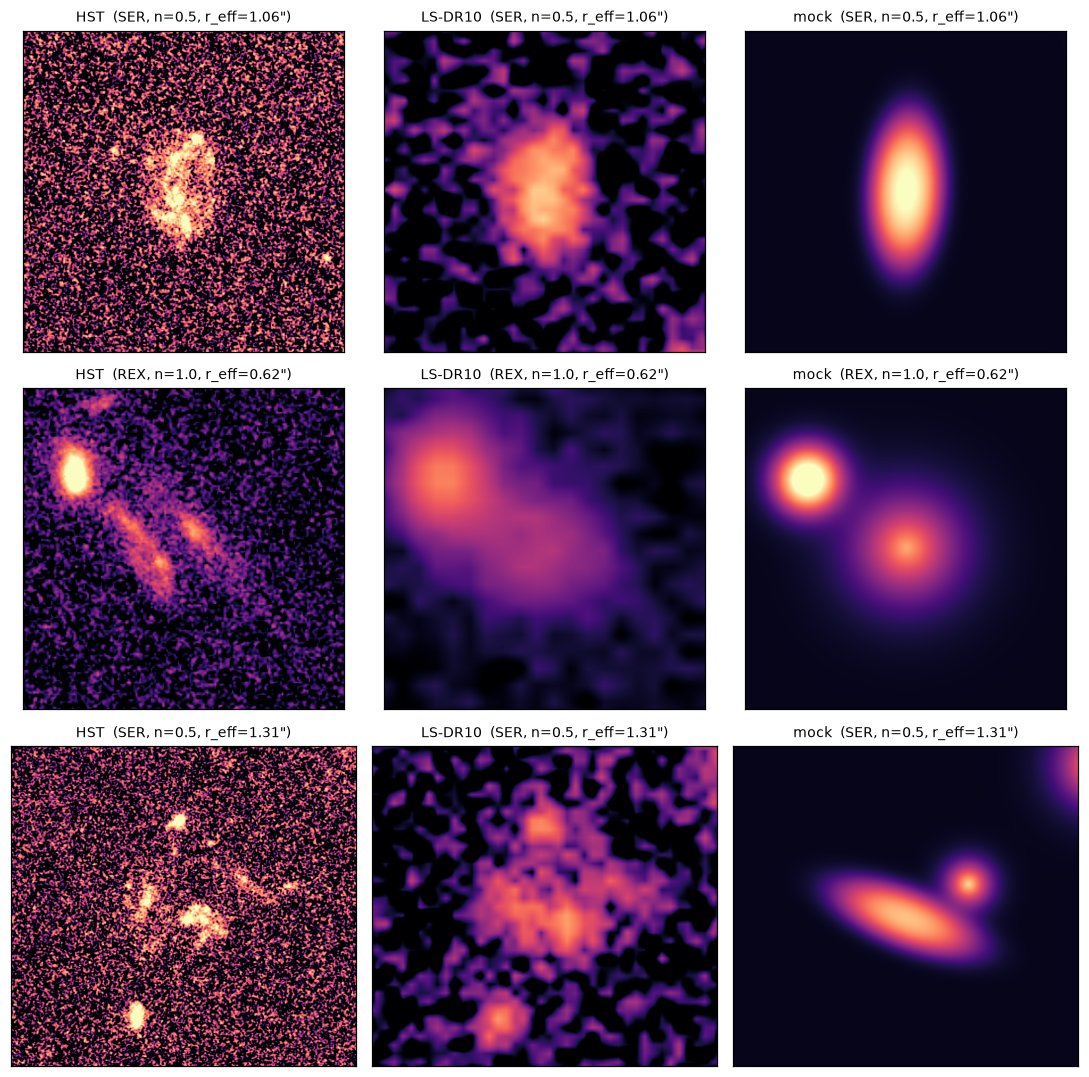

In [8]:
x, y = frame.wcs.world_to_pixel_values(truth["ra"], truth["dec"])
inside = (x > 150) & (x < nx - 150) & (y > 150) & (y < ny - 150)
cand = [i for i in np.argsort(truth["mag_ab_band"]) if inside[i] and truth["r_eff_arcsec"][i] > 0.5][:3]

fig, axes = plt.subplots(len(cand), 3, figsize=(10, 3.3 * len(cand)))
for row, i in zip(axes, cand):
    h = int(np.clip(4 * truth["r_eff_arcsec"][i], 2.5, 8.0) / pix)
    cx, cy = int(x[i]), int(y[i])
    sl = (slice(max(cy - h, 0), cy + h), slice(max(cx - h, 0), cx + h))
    local_hi = np.nanpercentile(hst_sb[sl], 99.5)
    for ax, img, name in zip(row, (hst_sb, ls_sb, mock_sb), ("HST", "LS-DR10", "mock")):
        ax.imshow(np.arcsinh(np.nan_to_num(img[sl]) / local_hi * 20.0) / np.arcsinh(20.0), origin="lower",
                  cmap="magma", vmin=-0.05, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{name}  ({truth['type'][i]}, n={truth['n'][i]:.1f}, r_eff={truth['r_eff_arcsec'][i]:.2f}\")",
                     fontsize=9)
fig.tight_layout()

## 7. Is the HST image registered to the LS astrometry?

A check on the HST world coordinates (the mosaic header carries leftover SIP terms that must be ignored). The HST
patch is blurred to roughly LS seeing and cross-correlated with the LS patch; the peak gives the offset.

In [9]:
def shift_arcsec(a, b, max_shift_px=60):
    a = np.nan_to_num(a - np.nanmean(a)); b = np.nan_to_num(b - np.nanmean(b))
    cc = np.fft.fftshift(np.real(np.fft.ifft2(np.fft.fft2(a) * np.conj(np.fft.fft2(b)))))
    cy, cx = np.array(cc.shape) // 2
    win = cc[cy - max_shift_px:cy + max_shift_px + 1, cx - max_shift_px:cx + max_shift_px + 1]
    j, i = np.unravel_index(np.argmax(win), win.shape)
    def parab(v):                      # sub-pixel peak along one axis
        return 0.5 * (v[0] - v[2]) / (v[0] - 2 * v[1] + v[2]) if v[0] - 2 * v[1] + v[2] != 0 else 0.0
    dj = j + parab(win[j - 1:j + 2, i]) - max_shift_px
    di = i + parab(win[j, i - 1:i + 2]) - max_shift_px
    return di * pix, dj * pix            # (+x, +y) offset of a relative to b

blur_px = 0.5 / pix                      # sigma = 0.5" -> FWHM 1.2" Gaussian, ~LS seeing
dx, dy = shift_arcsec(gaussian_filter(np.nan_to_num(hst_sb), blur_px), gaussian_filter(np.nan_to_num(ls_sb), 0.0))
print(f"HST - LS offset: dx = {dx:+.3f}\", dy = {dy:+.3f}\"  (x is east-left, y is north-up; 1 LS pixel = 0.262\")")

HST - LS offset: dx = -0.089", dy = +0.080"  (x is east-left, y is north-up; 1 LS pixel = 0.262")


## Reading the comparison

* HST resolves spiral arms, bars, clumps and compact cores that LS shows as one smooth blob.
* The mock follows the LS fit, so it places each galaxy correctly, with the right size, axis ratio and brightness, but
  as a featureless Sersic. Substructure and, below the LS depth, the whole faint population are missing.
* For a WCC (50 mas PSF) the HST image is the better "truth". The route forward is the existing `ImageComponent`
  (see notebook 11/12), which can place a real HST mosaic cutout into the frame, instead of Sersic fits.

## 8. How long would WCC need? Depth and substructure

Resolution is not the only gap between WCC and HST: how deep must a WCC stack go to see the clumps and arms HST
resolves? The comparison is made in **1-sigma surface-brightness noise** over a fixed angular scale (the
substructure is diffuse light), using

* the HST noise *measured* from this cutout, binned to each scale so that the correlated noise of drizzled data
  is included, and
* a WCC noise model from the simulator's own sky, dark and read-noise numbers, checked against `simulate_field`
  below.

First, how much exposure time does the HST image actually have here? CANDELS ships an exposure-time map on the
same grid as the mosaic (loaded in section 1).

In [10]:
exp_lo, exp_med, exp_hi = np.percentile(hst_exp, [5, 50, 95])
print(f"HST ACS {HST_BAND.upper()} exposure time over this patch: median {exp_med:.0f} s = {exp_med/3600:.2f} h "
      f"(5-95%: {exp_lo:.0f}-{exp_hi:.0f} s, full range {hst_exp.min():.0f}-{hst_exp.max():.0f} s)")

HST ACS F606W exposure time over this patch: median 5041 s = 1.40 h (5-95%: 3440-7421 s, full range 1221-10318 s)


### HST noise per angular scale

Sources are masked on a smoothed copy, then the clipped rms of the remaining pixels is taken in boxes of each size
and converted to nanomaggies per arcsec^2 (AB zero point 22.5).

In [11]:
from astropy.stats import sigma_clipped_stats
from scipy.ndimage import binary_dilation

HST_PIX = 0.030
nmgy_per_hst = 10.0 ** (0.4 * (22.5 - hst_zp))
smooth = gaussian_filter(hst, 3)
_, smed, ssd = sigma_clipped_stats(smooth, sigma=2.5)
src_mask = binary_dilation(smooth > smed + 3.5 * ssd, iterations=8)

def binned_sb(b):
    ny_, nx_ = (hst.shape[0] // b) * b, (hst.shape[1] // b) * b
    sums = hst[:ny_, :nx_].reshape(ny_ // b, b, nx_ // b, b).sum(axis=(1, 3))
    flag = src_mask[:ny_, :nx_].reshape(ny_ // b, b, nx_ // b, b).any(axis=(1, 3))
    return sums * nmgy_per_hst / (b * HST_PIX) ** 2, flag     # nmgy / arcsec^2

SCALES = {"0.12\"": 4, "0.30\"": 10, "0.51\"": 17}            # HST pixels per box side
hst_sigma = {}
for name, b in SCALES.items():
    sb, flag = binned_sb(b)
    hst_sigma[b * HST_PIX] = sigma_clipped_stats(sb[~flag], sigma=3)[2]
    print(f"HST 1-sigma over {name} boxes: {hst_sigma[b * HST_PIX]:.4f} nmgy/arcsec^2 "
          f"= mu {22.5 - 2.5 * np.log10(hst_sigma[b * HST_PIX]):.2f} mag/arcsec^2")

HST 1-sigma over 0.12" boxes: 0.0239 nmgy/arcsec^2 = mu 26.55 mag/arcsec^2
HST 1-sigma over 0.30" boxes: 0.0108 nmgy/arcsec^2 = mu 27.42 mag/arcsec^2
HST 1-sigma over 0.51" boxes: 0.0067 nmgy/arcsec^2 = mu 27.94 mag/arcsec^2


### WCC noise model, checked against the simulator

Per pixel, a stack of `n` frames of length `frame` has variance `t (sky + dark) + n read^2` electrons^2. Signal
and noise are summed over the `N` pixels of a box, so the 1-sigma surface brightness is
`sqrt(var) / (k sqrt(N) t)` with `k` the e-/s/pixel per nmgy/arcsec^2. The check simulates empty frames (no
sources, no wings) and compares the background statistics.

In [12]:
from wcc_sim import empty_catalog
from wcc_sim.pipeline import make_base_simulation
from wcc_sim.starflux import sky_and_dark_rates

sim = make_base_simulation(SENSORFILTER)
sky, dark = sky_and_dark_rates(sim)
read = float(sim.sensor.read_noise.value)
k = rate_for_ab(22.5, SENSORFILTER) * pix**2           # e-/s/pix per nmgy/arcsec^2
FRAME = 300.0

def wcc_var(t, frame=FRAME):
    return t * (sky + dark) + max(1, int(np.ceil(t / frame))) * read**2

def wcc_sigma_sb(t, scale, frame=FRAME):
    N = (scale / pix) ** 2
    return np.sqrt(wcc_var(t, frame)) / (k * np.sqrt(N) * t)

# simulator check: one frame, then a 12-frame stack (1 h) of independent noise realisations
frames = [simulate_field(RA, DEC, sensorfilter=SENSORFILTER, exptime=FRAME, shape=(400, 400), seed=s,
                         catalog=empty_catalog(), wings=False, scatter=False).image_e for s in range(12)]
print(f"1 x {FRAME:.0f} s: simulated mean {frames[0].mean():.2f} e-, std {frames[0].std():.3f} e-   "
      f"model mean {FRAME * (sky + dark):.2f}, std {np.sqrt(wcc_var(FRAME)):.3f}")
stack = np.sum(frames, axis=0)
print(f"12 x {FRAME:.0f} s: simulated mean {stack.mean():.1f} e-, std {stack.std():.2f} e-   "
      f"model mean {12 * FRAME * (sky + dark):.1f}, std {np.sqrt(wcc_var(12 * FRAME)):.2f}")

1 x 300 s: simulated mean 5.01 e-, std 3.781 e-   model mean 5.01, std 3.779
12 x 300 s: simulated mean 60.2 e-, std 13.08 e-   model mean 60.2, std 13.09


### Exposure needed to match HST's noise

Bisection on the model for the total time at which the WCC 1-sigma surface brightness equals HST's, for 300 s and
900 s frames. Short frames are read-noise limited (3 e- per frame against a sky of a few e- per 300 s), so longer
frames help until a bright star saturates.

In [13]:
def time_for(sigma_sb, scale, frame=FRAME):
    lo, hi = 1.0, 1e8
    for _ in range(90):
        mid = np.sqrt(lo * hi)
        lo, hi = (mid, hi) if wcc_sigma_sb(mid, scale, frame) > sigma_sb else (lo, mid)
    return hi

print(f"{'scale':>7} {'300 s frames':>14} {'900 s frames':>14}")
for scale, sig in hst_sigma.items():
    print(f"{scale:6.2f}\" {time_for(sig, scale)/3600:12.2f} h {time_for(sig, scale, 900.0)/3600:12.2f} h")
print(f"\nread noise is {read**2 / wcc_var(300.0):.0%} of the per-pixel variance in a 300 s frame, "
      f"{read**2 / wcc_var(900.0, 900.0):.0%} in a 900 s frame")

  scale   300 s frames   900 s frames
  0.12"         3.71 h         2.14 h
  0.30"         2.95 h         1.68 h
  0.51"         2.68 h         1.56 h

read noise is 65% of the per-pixel variance in a 300 s frame, 38% in a 900 s frame


### How deep is the substructure?

The brightness HST measures inside the resolved galaxies of this patch (0.3" boxes within 1.5 half-light radii
of the Tractor galaxies larger than 0.4") sets what WCC has to detect. Median levels sit near HST's own noise floor, so
only the brighter clumps and arms are detected at high S/N even in HST.

In [14]:
SC = 0.30
b = int(round(SC / HST_PIX))
sb, _ = binned_sb(b)
xh, yh = hst_wcs.world_to_pixel_values(truth["ra"], truth["dec"])
xh, yh = xh / b, yh / b
sel = ((truth["r_eff_arcsec"] > 0.4) & (truth["mag_ab_band"] < 24.2)
       & (xh > 3) & (xh < sb.shape[1] - 3) & (yh > 3) & (yh < sb.shape[0] - 3))
yy, xx = np.indices(sb.shape)
vals = [sb[((xx - xh[i]) ** 2 + (yy - yh[i]) ** 2) < (1.5 * truth["r_eff_arcsec"][i] / (b * HST_PIX)) ** 2]
        for i in np.where(sel)[0]]
vals = np.concatenate(vals) if vals else np.array([np.nan])
print(f"{int(sel.sum())} resolved galaxies, {vals.size} boxes of {SC}\"")
LEVELS = {}
print(f"{'':>13} {'mu':>6} {'HST S/N':>8} {'WCC time for S/N=5 (300 s frames)':>36} {'(900 s frames)':>16}")
for pct in (90, 75, 50):
    v = float(np.nanpercentile(vals, pct))
    LEVELS[f"{pct}th pct"] = v
    print(f"{pct:>3}th pct box {22.5 - 2.5 * np.log10(v):6.2f} {v / hst_sigma[SC]:8.1f} "
          f"{time_for(v / 5, SC) / 3600:30.2f} h {time_for(v / 5, SC, 900.0) / 3600:12.2f} h")

5 resolved galaxies, 346 boxes of 0.3"
                  mu  HST S/N    WCC time for S/N=5 (300 s frames)   (900 s frames)
 90th pct box  24.80     11.1                           0.62 h         0.37 h
 75th pct box  25.43      6.3                           1.88 h         1.10 h
 50th pct box  26.38      2.6                          10.82 h         6.16 h


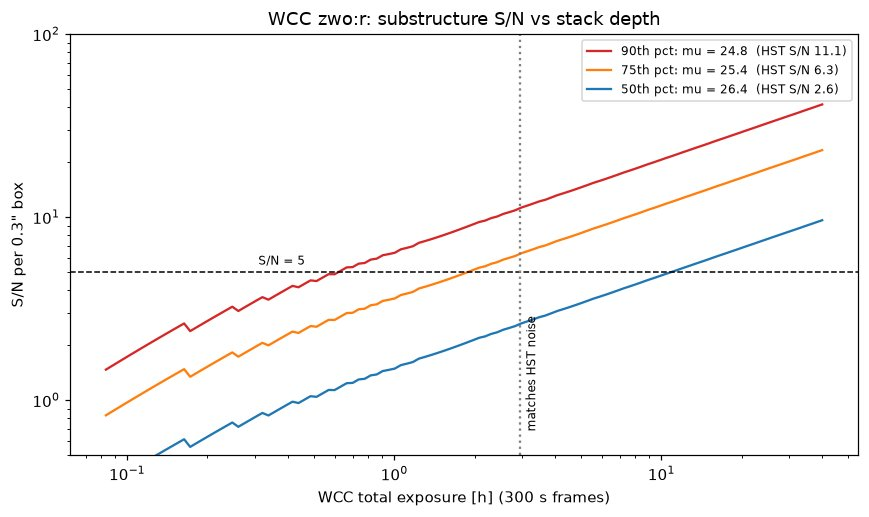

In [15]:
t_grid = np.logspace(np.log10(300), np.log10(40 * 3600), 120)
fig, ax = plt.subplots(figsize=(8, 4.8))
for (label, v), col in zip(LEVELS.items(), ("C3", "C1", "C0")):
    ax.plot(t_grid / 3600, v / np.array([wcc_sigma_sb(t, SC) for t in t_grid]), color=col,
            label=f"{label}: mu = {22.5 - 2.5 * np.log10(v):.1f}  (HST S/N {v / hst_sigma[SC]:.1f})")
ax.axhline(5, color="k", ls="--", lw=1); ax.text(0.31, 5.5, "S/N = 5", fontsize=8)
t_match = time_for(hst_sigma[SC], SC)
ax.axvline(t_match / 3600, color="gray", ls=":"); ax.text(t_match / 3600 * 1.05, 0.7, "matches HST noise", fontsize=8, rotation=90)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("WCC total exposure [h] (300 s frames)")
ax.set_ylabel(f"S/N per {SC}\" box"); ax.set_ylim(0.5, 100); ax.legend(fontsize=8)
ax.set_title(f"WCC {SENSORFILTER}: substructure S/N vs stack depth")
fig.tight_layout()

**Reading it.** WCC resolves the scale of HST's substructure (a ~50 mas PSF against HST's ~0.1" and LS's ~1"), and
the model says a few hours of stacked frames reach HST's noise per 0.3" box, while the brighter clumps need under two.
The model assumes a perfect stack: no alignment loss, flat-field error or sky-subtraction error, which usually limit
low-surface-brightness work before photon noise does. Saturation of bright stars in long frames is not checked.
The resolved sample here is small (the printed galaxy count), so the percentiles are rough.

## 9. Lazuli is bigger than HST: why isn't `zwo:r` much faster?

Lazuli's primary (3.065 m, 7.4 m^2) collects about 1.6 times HST's geometric area, and WCC's detectors are modern.
So one might expect a WCC image to reach HST-CANDELS depth in much less time. Two numbers decide whether it does:

1. the **detected rate per unit brightness**, in e-/s per nanomaggy, which folds in aperture, passband and
   throughput, and
2. the **noise per arcsec^2**, which depends on the sky, the dark current and, with fine pixels, the read noise.

The cells below compute both for HST F606W and for the `zwo:r` and broad `zwo:bb` filters.

In [16]:
def passband(sf):
    bp = make_base_simulation(sf).sensor.bandpass
    w = bp.waveset.to("nm").value
    tr = np.asarray(bp(bp.waveset))
    half = w[tr >= 0.5 * tr.max()]
    return half.min(), half.max()

hst_rate = 1.0 / nmgy_per_hst            # e-/s per nanomaggy for HST (from PHOTFLAM / PHOTPLAM)
rows = [("HST ACS F606W", hst_rate, "~470-720 nm (not measured here)")]
for sf in ("zwo:g", "zwo:r", "zwo:i", "zwo:bb"):
    lo_, hi_ = passband(sf)
    rows.append((f"Lazuli {sf}", rate_for_ab(22.5, sf), f"{lo_:.0f}-{hi_:.0f} nm (half maximum)"))
print(f"{'':16s} {'e-/s per nmgy':>14s}   passband")
for name, rate, band_ in rows:
    print(f"{name:16s} {rate:14.1f}   {band_}")
print(f"\ngeometric area: Lazuli {np.pi * (3.065 / 2) ** 2:.2f} m^2, HST {np.pi * (2.4 / 2) ** 2:.2f} m^2 "
      f"(ratio {(3.065 / 2.4) ** 2:.2f}; HST's obstruction is not subtracted)")

                  e-/s per nmgy   passband
HST ACS F606W              39.5   ~470-720 nm (not measured here)
Lazuli zwo:g               70.0   405-545 nm (half maximum)
Lazuli zwo:r               39.1   555-685 nm (half maximum)
Lazuli zwo:i               13.9   705-815 nm (half maximum)
Lazuli zwo:bb             111.3   435-685 nm (half maximum)

geometric area: Lazuli 7.38 m^2, HST 4.52 m^2 (ratio 1.63; HST's obstruction is not subtracted)


### Time for WCC to match HST's noise

For each filter and frame length, the stack time at which the 1-sigma surface brightness over 0.3" boxes equals
the HST value measured above. The "read share" is the fraction of the per-pixel variance that comes from read noise
at HST's median exposure time.

In [17]:
def make_model(sf):
    s = make_base_simulation(sf)
    sky_, dark_ = sky_and_dark_rates(s)
    rn_ = float(s.sensor.read_noise.value)
    k_ = rate_for_ab(22.5, sf) * pix**2
    npix = (SC / pix) ** 2
    def sigma(t, frame):
        n = max(1, int(np.ceil(t / frame)))
        return np.sqrt(t * (sky_ + dark_) + n * rn_**2) / (k_ * np.sqrt(npix) * t)
    def read_share(t, frame):
        n = max(1, int(np.ceil(t / frame)))
        return n * rn_**2 / (t * (sky_ + dark_) + n * rn_**2)
    return sky_, rn_, sigma, read_share

T_HST = float(np.median(hst_exp))
sig_hst = hst_sigma[SC]
FRAMES = (300.0, 900.0, 1800.0)
print(f"HST F606W: median {T_HST:.0f} s, 1-sigma over {SC}\" boxes = {sig_hst:.4f} nmgy/arcsec^2 "
      f"(mu {22.5 - 2.5 * np.log10(sig_hst):.2f})\n")
print(f"{'filter':8s} {'frame':>7s} {'time to match HST':>18s} {'noise at HST time':>18s} {'read share':>11s}")
for sf in ("zwo:r", "zwo:bb"):
    sky_, rn_, sigma, read_share = make_model(sf)
    for fr in FRAMES:
        lo_, hi_ = 1.0, 1e8
        for _ in range(90):
            mid = np.sqrt(lo_ * hi_)
            lo_, hi_ = (mid, hi_) if sigma(mid, fr) > sig_hst else (lo_, mid)
        print(f"{sf:8s} {fr:6.0f}s {hi_ / 3600:16.2f} h {sigma(T_HST, fr) / sig_hst:15.2f}x HST {read_share(T_HST, fr):10.0%}")
    print(f"{'':8s} sky {sky_ / pix**2:.1f} e-/s/arcsec^2; read noise {rn_:.2f} e- = {rn_**2 / pix**2:,.0f} e-^2 per arcsec^2 per read")

HST F606W: median 5041 s, 1-sigma over 0.3" boxes = 0.0108 nmgy/arcsec^2 (mu 27.42)

filter     frame  time to match HST  noise at HST time  read share
zwo:r       300s             2.95 h            1.45x HST        65%
zwo:r       900s             1.68 h            1.10x HST        40%
zwo:r      1800s             1.37 h            0.99x HST        25%
         sky 47.9 e-/s/arcsec^2; read noise 3.04 e- = 32,568 e-^2 per arcsec^2 per read
zwo:bb      300s             0.53 h            0.60x HST        46%
zwo:bb      900s             0.38 h            0.51x HST        23%
zwo:bb     1800s             0.33 h            0.48x HST        13%
         sky 117.0 e-/s/arcsec^2; read noise 3.04 e- = 32,568 e-^2 per arcsec^2 per read


### Why `zwo:r` does not reach HST depth much faster

* **The bigger mirror is cancelled by the narrower filter.** Lazuli collects about 1.6 times HST's area, but `zwo:r`
  passes roughly half of F606W's bandwidth, so the two detect almost the same e-/s per nanomaggy (about 39 for both).
  A flat-spectrum faint source is not brighter to Lazuli in `zwo:r` than to HST in F606W. In the broad `zwo:bb`
  filter, which is close to F606W in width, the rate is nearly three times higher, and that is where Lazuli's
  aperture shows up.
* **Fine pixels make read noise costly.** The noise per arcsec^2 from reading out is `read^2 / pixel_area`: with
  16.9 mas pixels that is about 33,000 e-^2 per arcsec^2 for every read, and ACS's native 50 mas pixels hold roughly nine
  times fewer pixels per arcsec^2. A modern low-read-noise detector does not help if each frame has to be read
  many times: with 300 s frames, read noise is about two thirds of the variance at HST's median exposure time. Longer
  frames fix most of this, which is why the 900 s and 1800 s rows are so much faster than 300 s.
* **The sky is not lower.** The ETC's `zwo:r` sky is about 22.3 mag/arcsec^2 (config zodi r = 22.5), and nothing here
  shows HST seeing a brighter sky in COSMOS. The sky term is the same order for both and does not change the
  conclusion; it has not been compared with the real HST sky in these exposures.
* **HST's measured noise is correlated, the WCC model is not.** Drizzling raises HST's noise above the
  independent-pixel expectation at these scales (the ratio printed in section 8). The model treats WCC pixels as
  independent, which flatters WCC; a resampled WCC stack would need longer than the table says.

**What this suggests.** To beat HST-CANDELS depth quickly, use the broad `zwo:bb` filter and frames of 900 s or
more, subject to saturation limits on bright stars, which are not checked here. In `zwo:r` the gain over HST is small
because the filter is narrow, not because of the telescope or detector.

## 10. A WCC mock built from an HST-derived catalog

**Is there a catalog in the HST data downloaded here?** No. What `candels_cutout.py` fetches is images only: a cutout of
the CANDELS F606W mosaic and the matching exposure-time map. The mosaic files carry no source list. Catalogs of the same
sky exist elsewhere, and the following were found at IRSA for this position:

* `acs_iphot_sep07`: ACS I-band (F814W) photometry for every source, with SExtractor shapes (no Sersic index);
* `cosmos_morph_zurich_1` (ZEST): GIM2D Sersic fits to the same ACS images, but the fit is `NaN` for most galaxies
  (only 4 of the 12 ZEST galaxies in this patch have one);
* `cosmos_morph_cassata_1_1`, `cosmos_morph_tasca_1_1`: half-light radius and axis ratio only.

These describe the original, shallower ACS F814W survey, not the deeper CANDELS F606W image shown above, and the angle
convention of their shapes did not agree with the pixels in a first test, so they are not used here. CANDELS' own
catalogs (multiwavelength photometry, structural fits) were not checked, because the VizieR server timed out.

**Instead the catalog is extracted from the F606W cutout itself** (`scripts/hst_catalog_mock.py`, with `photutils`).
Positions, sizes, axis ratios and position angles are then measured in the frame the image is in, in the band closest to
`zwo:r`, at the depth of the image. Each source becomes one Sersic component, exponential (n = 1) unless ZEST has a GIM2D
index for it. Sizes have the HST PSF removed in quadrature and the Gaia stars are left to the simulator.

157 HST sources (S/N cut), 154 kept as Sersic components; AB mag 10/50/90%: [25.0, 26.7, 28.2]
4 of them take their Sersic index from the ZEST GIM2D fit, the rest are n = 1
Legacy Surveys mock for comparison: 123 Sersic components


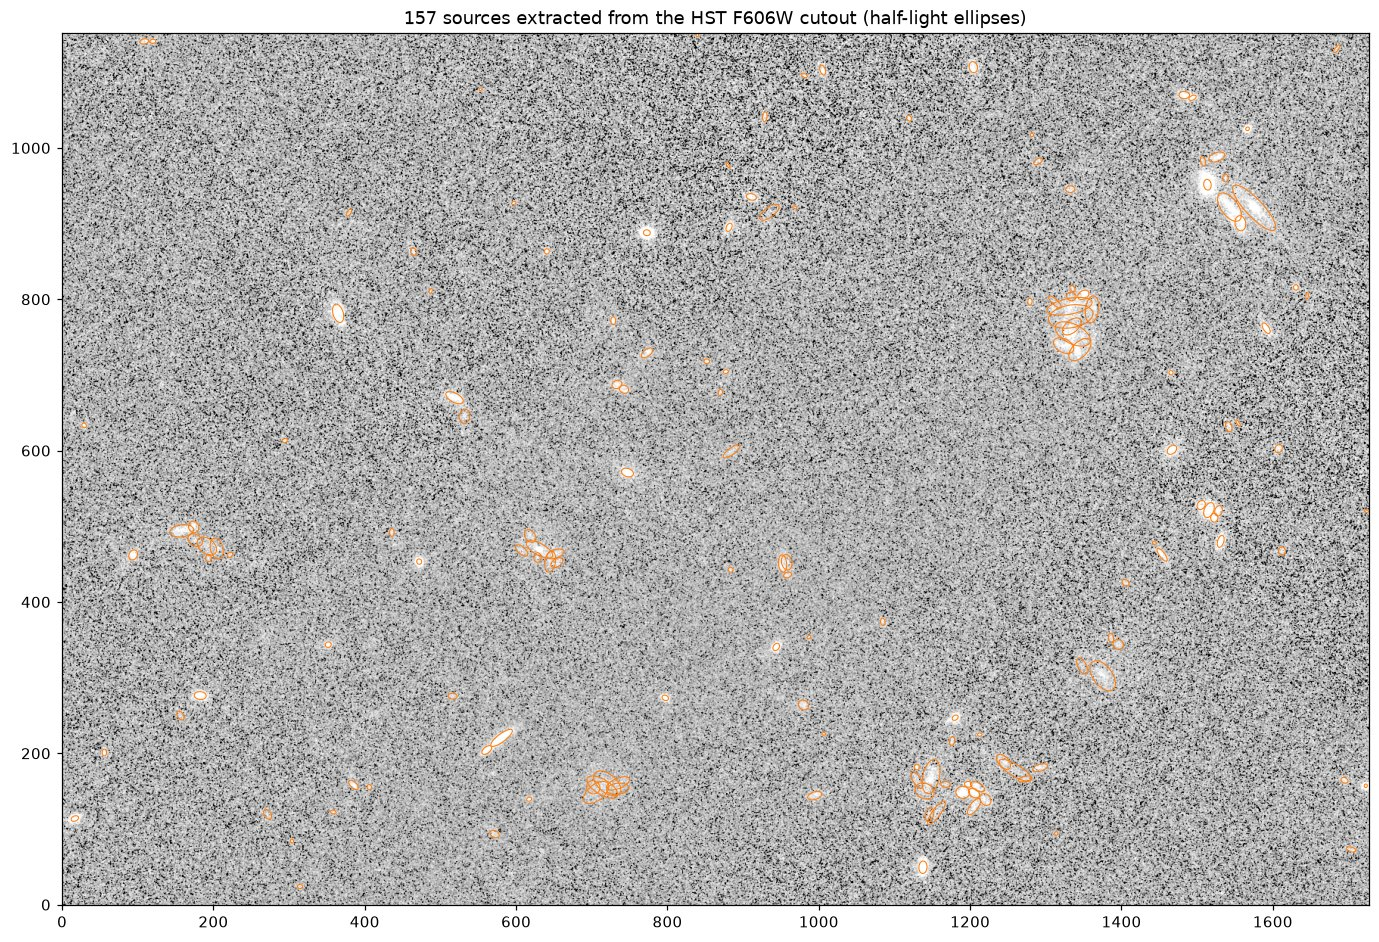

In [18]:
hst_tab = hcm.detect_hst_sources(hst, hst_wcs, hst_zp, min_snr=7.0)
zest_n = hcm.zest_sersic_n(hst_tab["ra"], hst_tab["dec"], 60, cache_dir=CACHE)
gaia_cat = query_gaia(RA, DEC, half_diag + 10.0, mag_limit=21.0, cache_dir=os.path.join(CACHE, "gaia"))
comps_h, truth_h = hcm.catalog_to_sersic(hst_tab, hst_wcs, frame, SENSORFILTER, n_sersic=zest_n, gaia=gaia_cat)
print(hcm.count_summary(hst_tab, comps_h))
print(f"{int(np.isfinite(zest_n).sum())} of them take their Sersic index from the ZEST GIM2D fit, the rest are n = 1")
print(f"Legacy Surveys mock for comparison: {len(comps)} Sersic components")

fig, ax = plt.subplots(figsize=(13, 13 * hst.shape[0] / hst.shape[1]))
lo_, hi_ = np.percentile(hst, [5, 99.7])
ax.imshow(np.arcsinh((hst - lo_) / (hi_ - lo_) * 40) / np.arcsinh(40), origin="lower", cmap="gray", vmin=0, vmax=1)
for r in hst_tab:
    q = 1 - r["ellip"]; rm = r["r_circ_arcsec"] / np.sqrt(q) / HST_PIX
    ax.add_patch(Ellipse((r["x"], r["y"]), 2 * rm, 2 * rm * q, angle=r["theta_pix"], fill=False, ec="C1", lw=0.7))
ax.set_title(f"{len(hst_tab)} sources extracted from the HST {HST_BAND.upper()} cutout (half-light ellipses)")
fig.tight_layout()

### Simulate it

Same instrument model, frame length and stack depths as section 4. The noise-free frame (at the 300 s single-frame
exposure) is the reference.

In [19]:
field_h = simulate_field(RA, DEC, sensorfilter=SENSORFILTER, exptime=EXPTIME, shape=SHAPE, seed=1,
                         extended_sources=comps_h, add_noise=False, cache_dir=os.path.join(CACHE, "gaia"))
mock_h_sb = rate_to_nmgy(field_h.image_clean / EXPTIME) / pix**2
mock_h_sb = mock_h_sb - np.nanmedian(mock_h_sb)

stacks_h = {}
for seed, hours in enumerate(STACK_HOURS, start=21):
    T = hours * 3600.0
    st = simulate_field(RA, DEC, sensorfilter=SENSORFILTER, exptime=T, n_reads=int(round(T / FRAME_LEN)),
                        shape=SHAPE, seed=seed, extended_sources=comps_h, cache_dir=os.path.join(CACHE, "gaia"))
    sb_ = rate_to_nmgy(st.image_e / T) / pix**2
    stacks_h[hours] = sb_ - np.nanmedian(sb_)
    print(f"{hours:>2} h: {int(st.saturation_mask.sum())} saturated pixels")

 1 h: 0 saturated pixels


 3 h: 0 saturated pixels


10 h: 0 saturated pixels


### HST, the Legacy-Surveys-based mock and the HST-catalog mock

Top row: the real HST image and, for comparison, the Legacy Surveys mock at 10 h from section 4. Then the HST-catalog
mock at 1, 3 and 10 h, and its noise-free version. One stretch throughout.

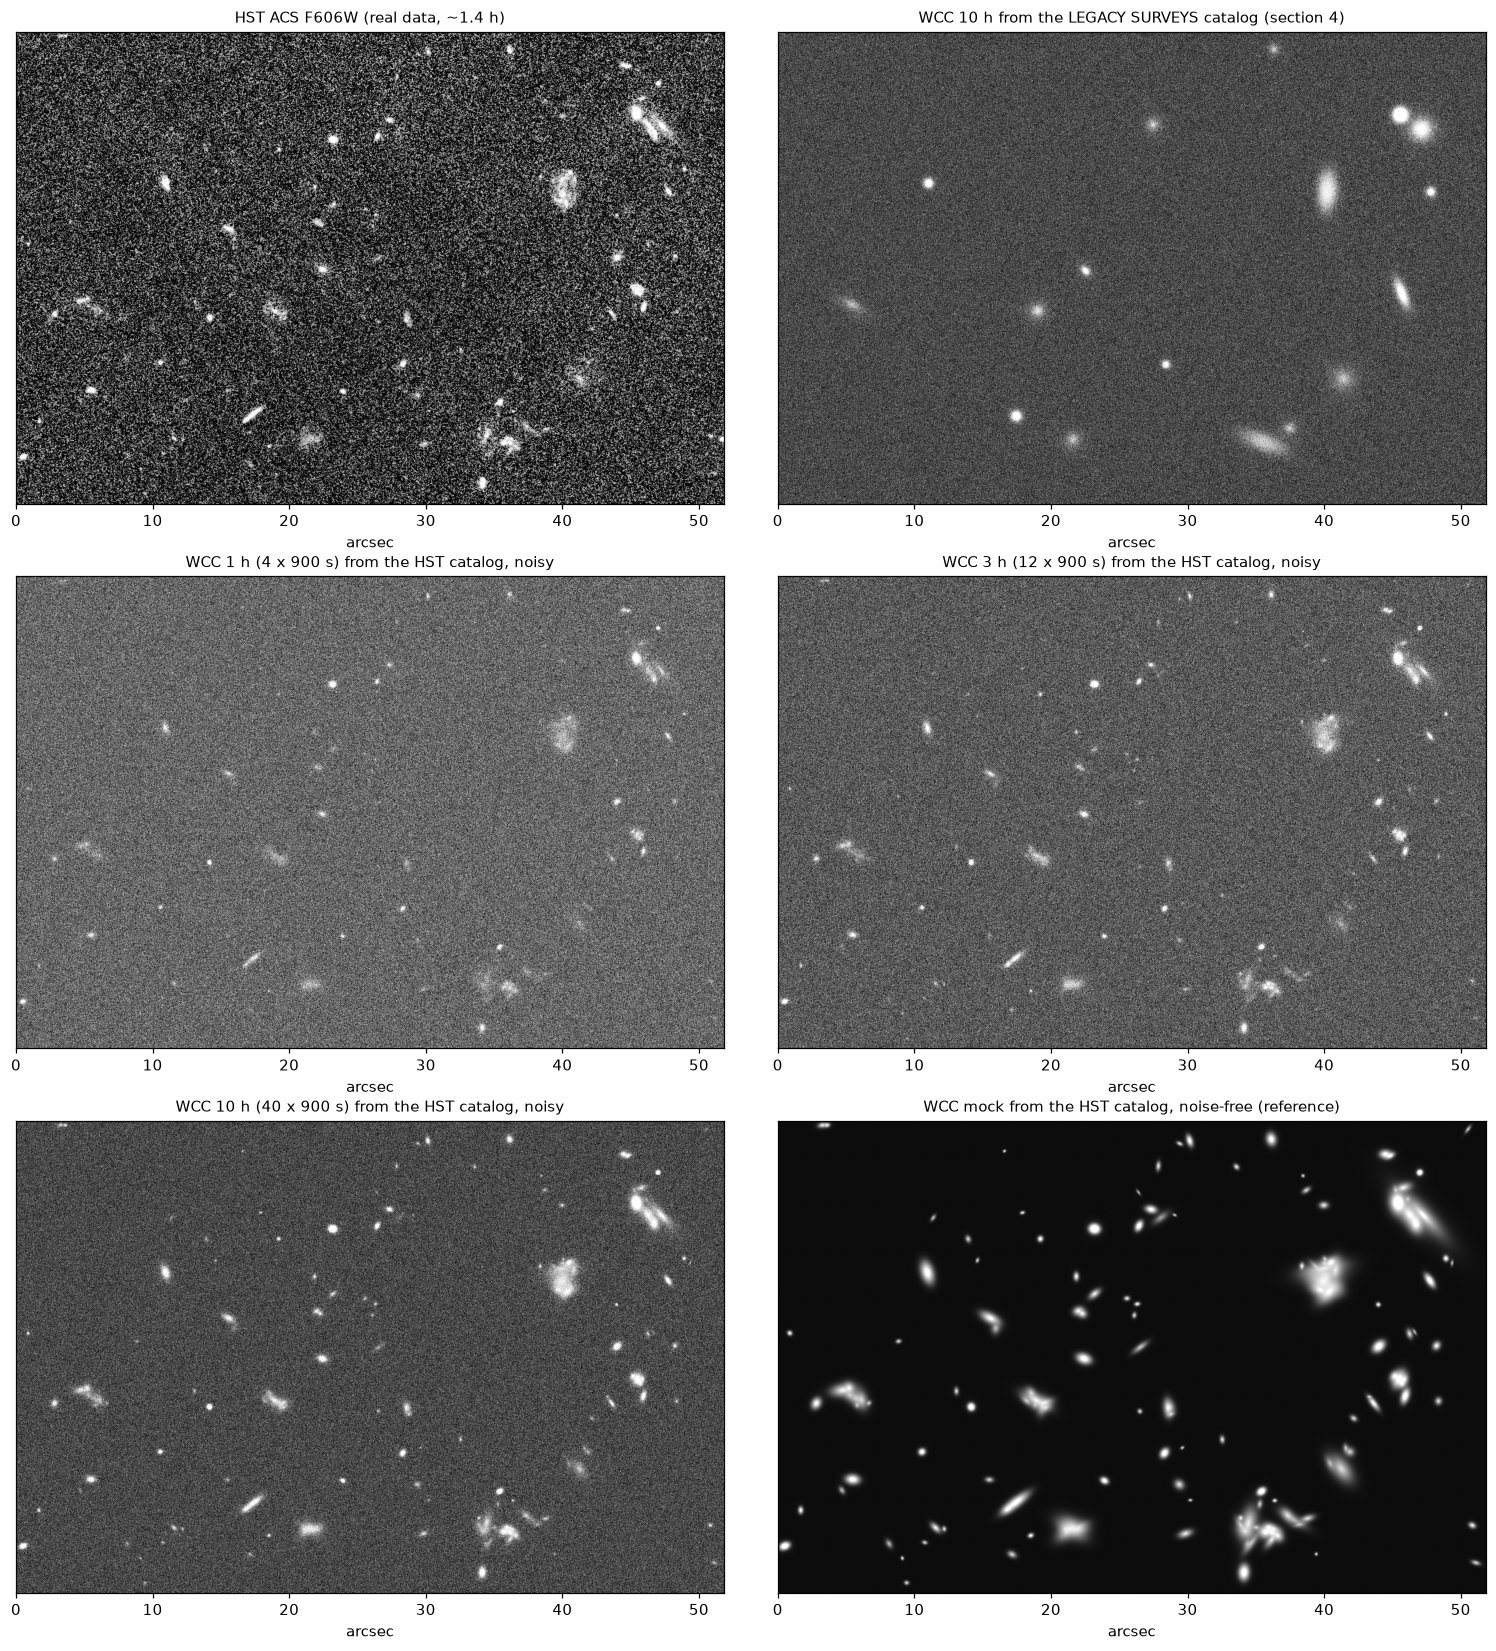

In [20]:
fig, axes = plt.subplots(3, 2, figsize=(14, 3 * 7.0 * height / width + 1.0))
show(axes[0, 0], hst_sb, f"HST ACS {HST_BAND.upper()} (real data, ~{np.median(hst_exp)/3600:.1f} h)")
show(axes[0, 1], stacks[10], "WCC 10 h from the LEGACY SURVEYS catalog (section 4)")
for ax, hours in zip((axes[1, 0], axes[1, 1], axes[2, 0]), STACK_HOURS):
    show(ax, stacks_h[hours], f"WCC {hours} h ({int(round(hours * 3600 / FRAME_LEN))} x {FRAME_LEN:.0f} s) from the HST catalog, noisy")
show(axes[2, 1], mock_h_sb, "WCC mock from the HST catalog, noise-free (reference)")
fig.tight_layout()

### The same galaxies up close

The three galaxies of section 6: real HST, the Legacy-Surveys-based mock (noise-free), the HST-catalog mock
(noise-free), and the HST-catalog mock after 10 h of noisy WCC observing.

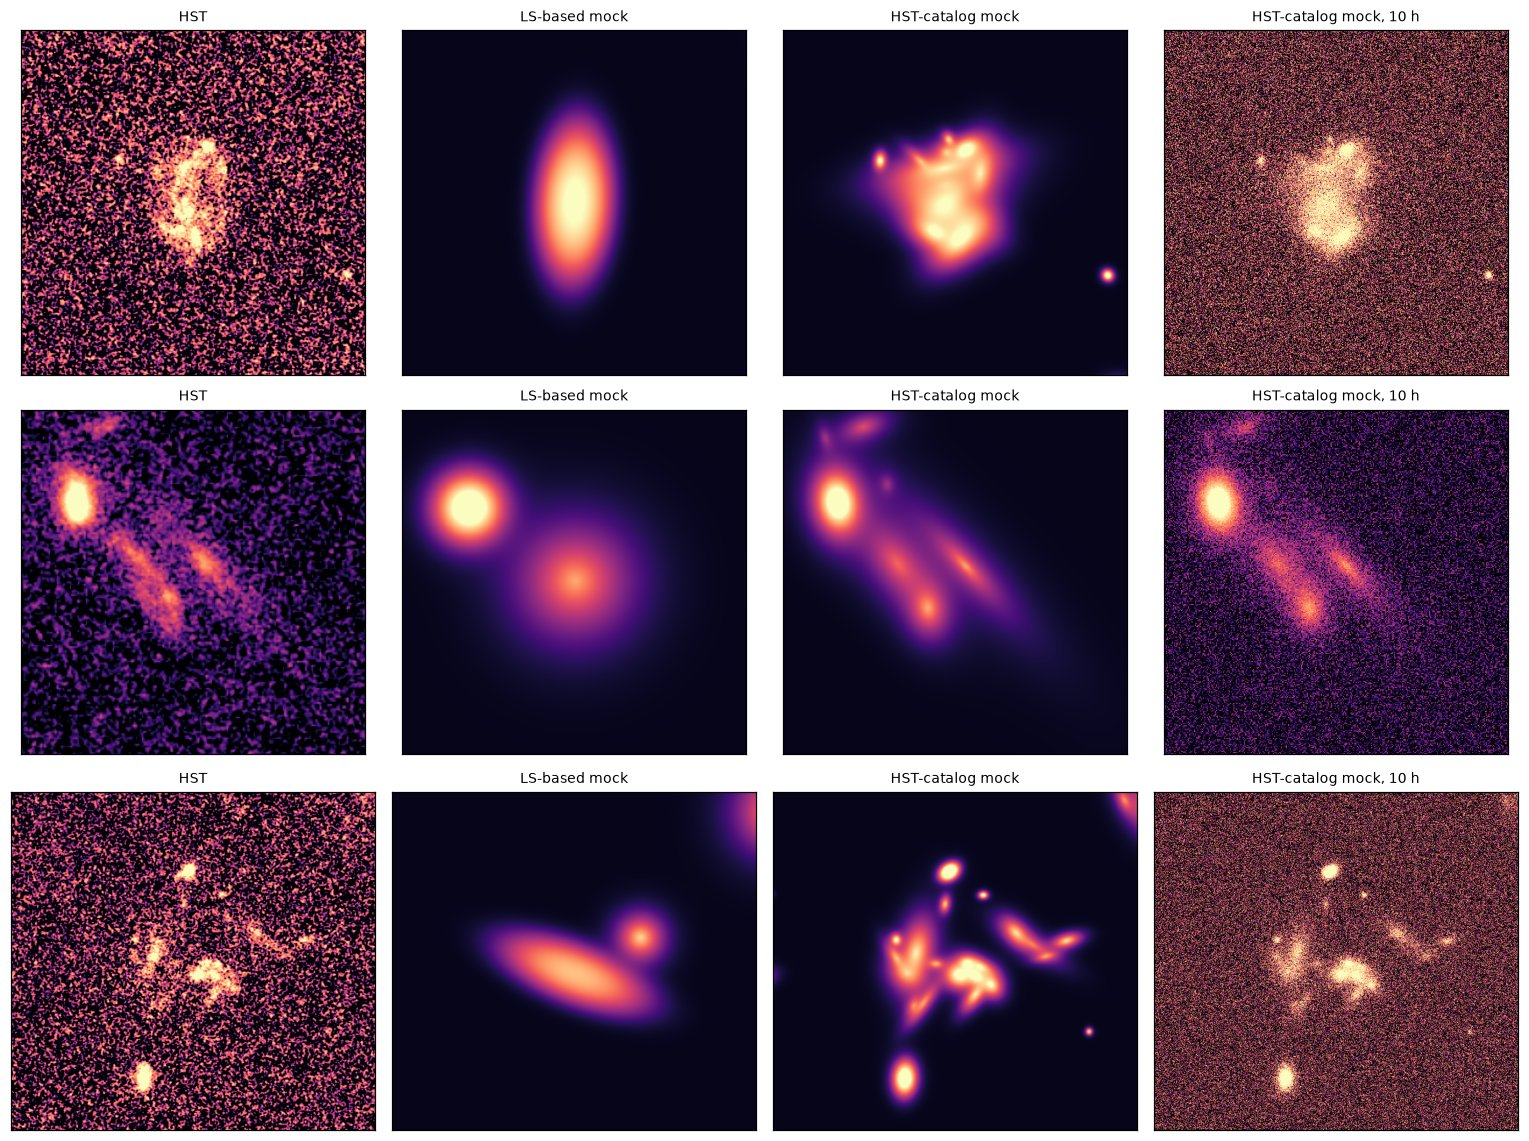

In [21]:
fig, axes = plt.subplots(len(cand), 4, figsize=(14, 3.5 * len(cand)))
for row, i in zip(axes, cand):
    h = int(np.clip(4 * truth["r_eff_arcsec"][i], 2.5, 8.0) / pix)
    cx, cy = int(x[i]), int(y[i])
    sl = (slice(max(cy - h, 0), cy + h), slice(max(cx - h, 0), cx + h))
    local_hi = np.nanpercentile(hst_sb[sl], 99.5)
    panels = ((hst_sb, "HST"), (mock_sb, "LS-based mock"), (mock_h_sb, "HST-catalog mock"), (stacks_h[10], "HST-catalog mock, 10 h"))
    for ax, (img, name) in zip(row, panels):
        ax.imshow(np.arcsinh(np.nan_to_num(img[sl]) / local_hi * 20.0) / np.arcsinh(20.0), origin="lower",
                  cmap="magma", vmin=-0.05, vmax=1)
        ax.set_xticks([]); ax.set_yticks([]); ax.set_title(name, fontsize=9)
fig.tight_layout()